# Assignment 2: Module 1, Fuzzy Logic

---

## Practical 9: Defuzzification Methods (Centroid, Bisector, Mean of Maximum)

### Aim
To apply and compare defuzzification methods on the same aggregated fuzzy output.

### Theory
Defuzzification turns a fuzzy output set into one crisp value. The methods used here are:
- **Centroid**: the centre of gravity of the area, $z^* = \dfrac{\int z\,\mu(z)\,dz}{\int \mu(z)\,dz}$
- **Bisector**: the point that splits the area into two equal halves.
- **Mean of Maximum (MOM)**: the average of all points where the membership is at its maximum.
- **Smallest / Largest of Maximum (SOM / LOM)**: the smallest and largest points where the maximum is reached.

### Implementation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

# 1. Output universe
z = np.arange(0, 10.01, 0.01)

# 2. Two output sets, each clipped at its rule firing strength, then aggregated with max
set1 = fuzz.trimf(z, [0, 3, 6])
set2 = fuzz.trimf(z, [4, 7, 10])
aggregated = np.fmax(np.fmin(0.8, set1), np.fmin(0.6, set2))


In [2]:
# 3. Apply each defuzzification method
methods = ["centroid", "bisector", "mom", "som", "lom"]
labels = {
    "centroid": "Centroid",
    "bisector": "Bisector",
    "mom": "Mean of Maximum",
    "som": "Smallest of Maximum",
    "lom": "Largest of Maximum",
}

crisp = {}
for m in methods:
    crisp[m] = fuzz.defuzz(z, aggregated, m)
    print(f"{labels[m]:<20}: {crisp[m]:.3f}")


Centroid            : 4.858
Bisector            : 4.558
Mean of Maximum     : 3.000
Smallest of Maximum : 2.410
Largest of Maximum  : 3.590


In [3]:
# 4. Check the centroid by hand: sum(z * mu) / sum(mu)
manual_centroid = np.sum(z * aggregated) / np.sum(aggregated)
print(f"Manual centroid = {manual_centroid:.3f}")


Manual centroid = 4.858


### Visualization


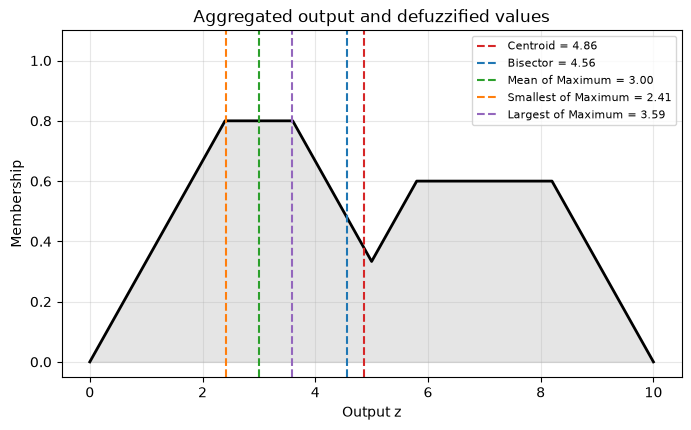

In [4]:
plt.figure(figsize=(8, 4.5))
plt.plot(z, aggregated, color="black", linewidth=2)
plt.fill_between(z, aggregated, alpha=0.2, color="gray")

colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple"]
for m, c in zip(methods, colors):
    plt.axvline(crisp[m], color=c, linestyle="--", label=f"{labels[m]} = {crisp[m]:.2f}")

plt.xlabel("Output z")
plt.ylabel("Membership")
plt.title("Aggregated output and defuzzified values")
plt.ylim(-0.05, 1.1)
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()


### Observation
- Centroid gives 4.858 and the manual calculation gives the same value.
- Bisector gives 4.558, which is a little lower, because the area is split at a different point.
- MOM gives 3.000. This is the middle of the plateau at membership 0.8, which lies between 2.41 (smallest of maximum) and 3.59 (largest of maximum).
- Centroid and bisector use the whole shape, while MOM and its variants depend only on the top of the shape.

### Conclusion
Five defuzzification methods were applied to one aggregated output. The centroid was verified by hand, and the results were compared on a plot.
